# **Exploratory Data Analysis (EDA) – Sample Superstore**

**Project Objective :**

To analyze retail sales and profit data using Python, Pandas, and Matplotlib to identify business trends, product performance, and opportunities to improve profitability.

In [19]:
import pandas as pd
df=pd.read_csv('/content/SampleSuperstore.csv')
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub_Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.96,2.0,0.00,41.91
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.94,3.0,0.00,219.58
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.62,2.0,0.00,6.87
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.58,5.0,0.45,-383.03
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.37,2.0,0.20,2.52


In [20]:
df.shape

(9994, 13)

In [21]:
print(df_clean.columns.tolist())

['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub_Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [22]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub_Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub_Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   float64
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(4), int64(1), object(8)
memory usage: 1015.1+ KB


In [24]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55190.379428,229.858022,3.789574,0.156203,28.656973
std,32063.693350,623.245131,2.225110,0.206452,234.260203
min,1040.000000,0.440000,1.000000,0.000000,-6599.980000
25%,23223.000000,17.280000,2.000000,0.000000,1.730000
50%,56430.500000,54.490000,3.000000,0.200000,8.665000
75%,90008.000000,209.940000,5.000000,0.200000,29.360000
max,99301.000000,22638.480000,14.000000,0.800000,8399.980000


In [25]:
df.isnull().sum()

,0
Ship Mode,0
Segment,0
Country,0
City,0
State,0
Postal Code,0
Region,0
Category,0
Sub_Category,0
Sales,0


In [26]:
df.duplicated().sum()

np.int64(17)

In [27]:
df[df.duplicated()]

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub_Category,Sales,Quantity,Discount,Profit
950,Standard Class,Home Office,United States,Philadelphia,Pennsylvania,19120,East,Office Supplies,Paper,15.55,3.0,0.2,5.44
3406,Standard Class,Home Office,United States,Columbus,Ohio,43229,East,Furniture,Chairs,281.37,2.0,0.3,-12.06
3670,Standard Class,Consumer,United States,Salem,Oregon,97301,West,Office Supplies,Paper,10.37,2.0,0.2,3.63
4117,Standard Class,Consumer,United States,Los Angeles,California,90036,West,Office Supplies,Paper,19.44,3.0,0.0,9.33
4553,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,12.84,3.0,0.0,5.78
5905,Same Day,Home Office,United States,San Francisco,California,94122,West,Office Supplies,Labels,41.40,4.0,0.0,19.87
6146,Standard Class,Corporate,United States,San Francisco,California,94122,West,Office Supplies,Art,11.76,4.0,0.0,3.18
6334,Standard Class,Consumer,United States,New York City,New York,10011,East,Office Supplies,Paper,49.12,4.0,0.0,23.09
6357,Standard Class,Corporate,United States,Seattle,Washington,98103,West,Office Supplies,Paper,25.92,4.0,0.0,12.44
7608,Standard Class,Consumer,United States,San Francisco,California,94122,West,Office Supplies,Paper,25.92,4.0,0.0,12.44


In [28]:
df_clean=df.drop_duplicates()
print("original rows:",len(df))
print("Rows after cleaning:",len(df_clean))
print("Duplicates Remaining:",df_clean.duplicated().sum())

original rows: 9994
Rows after cleaning: 9977
Duplicates Remaining: 0


In [29]:
df_clean['Category'].unique()

array(['Furniture', 'Office Supplies', 'Technology'], dtype=object)

In [30]:
df_clean['Category'].value_counts()

,count
Category,
Office Supplies,6012
Furniture,2118
Technology,1847


In [31]:
df_clean['Region'].value_counts()

,count
Region,
West,3193
East,2845
Central,2319
South,1620


In [32]:
total_sales=df_clean['Sales'].sum()
total_profit=df_clean['Profit'].sum()
print("Total Sales:",round(total_sales,2))
print("Total Profit:",round(total_profit,2))


Total Sales: 2296195.81
Total Profit: 286242.2


In [33]:
Sub_Category_profit = df_clean.groupby('Sub_Category')['Profit'].sum()

loss_making = Sub_Category_profit[Sub_Category_profit < 0]

loss_making.sort_values()

,Profit
Sub_Category,
Tables,-17725.59
Bookcases,-3472.56
Supplies,-1188.99


In [34]:
category_profit=df_clean.groupby('Category')['Profit'].sum()
print(category_profit.sort_values(ascending=False))

Category
Technology         145455.66
Office Supplies    122364.75
Furniture           18421.79
Name: Profit, dtype: float64


**Review of Loss-Making Sub-Categories**

The analysis identified three sub-categories with negative total profit: Tables ($-17,725.59), Bookcases ($-3,472.56), and Supplies ($-1,188.99).

Tables recorded the largest loss. The business should investigate product pricing, discount levels, and costs to identify opportunities to improve profitability.

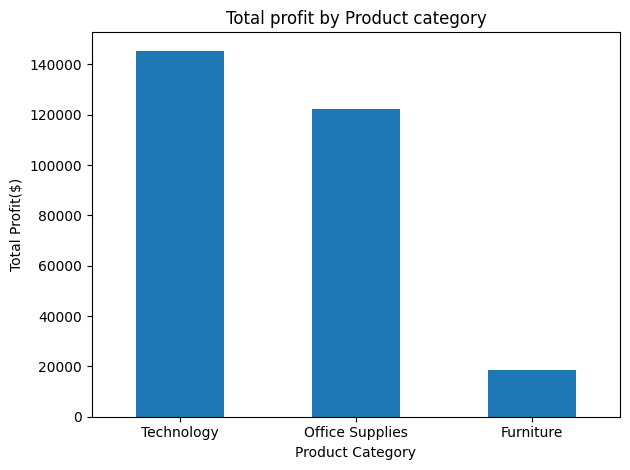

In [35]:
import matplotlib.pyplot as plt

category_profit=df_clean.groupby('Category')['Profit'].sum()
category_profit=category_profit.sort_values(ascending=False)


category_profit.plot(kind="bar")

plt.title('Total profit by Product category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
region_sales=df_clean.groupby('Region')['Sales'].sum()
print(region_sales.sort_values(ascending=False))

Region
West       725255.74
East       678435.32
Central    500782.85
South      391721.90
Name: Sales, dtype: float64


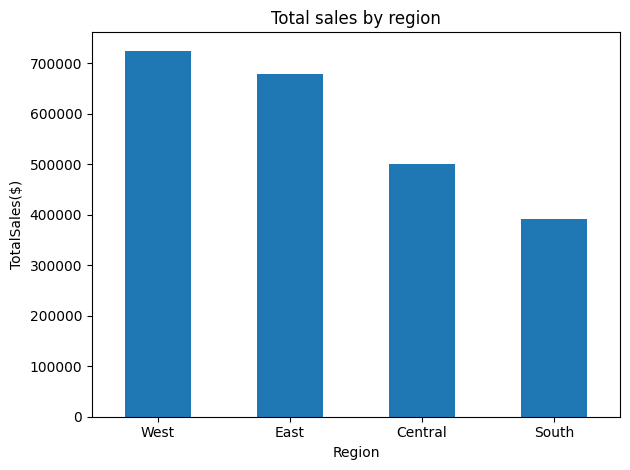

In [37]:
import matplotlib.pyplot as plt
region_sales=region_sales.sort_values(ascending=False)
region_sales.plot(kind='bar')

plt.title("Total sales by region")
plt.xlabel("Region")
plt.ylabel("TotalSales($)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [38]:
import pandas as pd
df=pd.read_csv('/content/SampleSuperstore.csv')
df_clean=df.drop_duplicates()

In [39]:
df_clean.shape

(9977, 13)

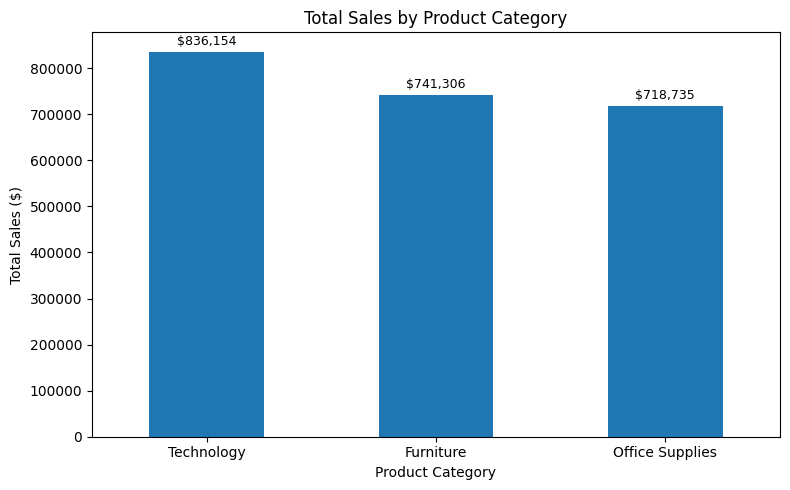

In [40]:
import matplotlib.pyplot as plt

category_sales = df_clean.groupby('Category')['Sales'].sum()
category_sales = category_sales.sort_values(ascending=False)

ax = category_sales.plot(kind='bar', figsize=(8, 5))

# Display sales values above each bar
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'${height:,.0f}',
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
region_profit = (
    df_clean.groupby('Region')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print(region_profit)

Region
West       108330.15
East        91506.37
South       46749.71
Central     39655.97
Name: Profit, dtype: float64


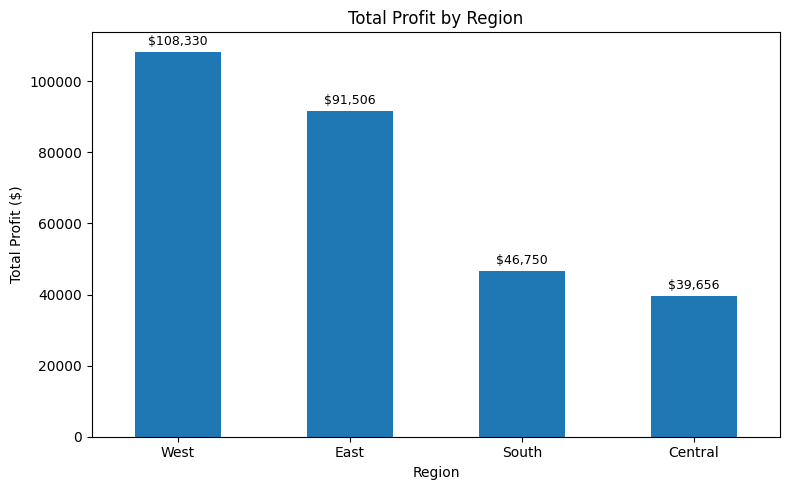

In [42]:
import matplotlib.pyplot as plt

ax = region_profit.plot(kind='bar', figsize=(8, 5))

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'${height:,.0f}',
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        fontsize=9
    )

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
subcategory_profit = (
    df_clean.groupby('Sub_Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

print(subcategory_profit)

Sub_Category
Copiers        55617.90
Phones         44516.25
Accessories    41936.78
Paper          33944.02
Binders        30227.88
Chairs         26567.11
Storage        21279.05
Appliances     18138.07
Furnishings    13052.83
Envelopes       6964.10
Art             6524.78
Labels          5526.31
Machines        3384.73
Fasteners        949.53
Supplies       -1188.99
Bookcases      -3472.56
Tables        -17725.59
Name: Profit, dtype: float64


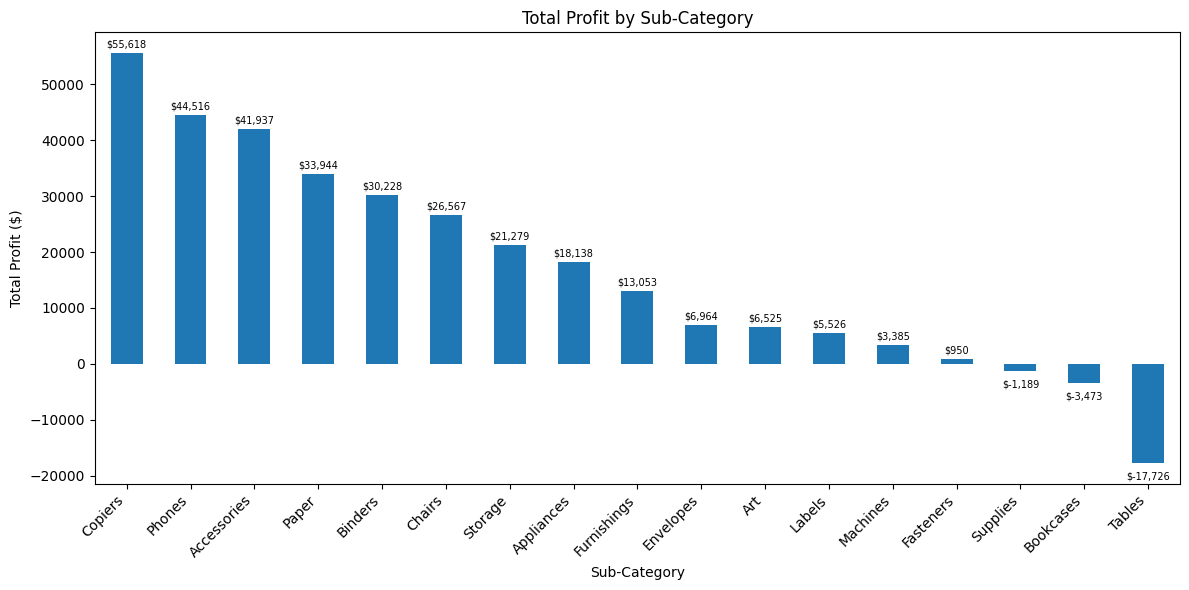

In [44]:
import matplotlib.pyplot as plt

ax = subcategory_profit.plot(
    kind='bar',
    figsize=(12, 6)
)

for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f'${height:,.0f}',
        (bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4 if height >= 0 else -12),
        textcoords='offset points',
        ha='center',
        fontsize=7
    )

plt.title('Total Profit by Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [45]:
subcategory_profit.head(5)

,Profit
Sub_Category,
Copiers,55617.90
Phones,44516.25
Accessories,41936.78
Paper,33944.02
Binders,30227.88


In [46]:
subcategory_profit.tail(5)

,Profit
Sub_Category,
Machines,3384.73
Fasteners,949.53
Supplies,-1188.99
Bookcases,-3472.56
Tables,-17725.59


**Business Recommendations**

1. Focus on Technology: Technology generated the highest total profit of approximately $145,456. The business should continue evaluating opportunities to grow this category.

2. Improve Furniture Profitability: Furniture generated approximately $18,422 in profit, much lower than Technology and Office Supplies. The business should investigate product costs, discounts, and pricing in this category.

3. Review Loss-Making Products: Identify sub-categories with negative profit and investigate whether excessive discounts or high costs are contributing to losses.

4. Analyze Regional Performance: Compare sales and profit across regions to identify strong-performing markets and regions that may need improvement.

5. Monitor Profit Margins: Track profit margins alongside total sales so that increasing sales does not come at the expense of profitability.

**Conclusion**

In this project, Exploratory Data Analysis (EDA) was performed on the Sample Superstore retail dataset using Python, Pandas, and Matplotlib.

The dataset was cleaned by identifying and removing duplicate records, and missing values were checked. Sales and profitability were analyzed across product categories and sub-categories.

The analysis identified total sales of approximately $2.30 million and profit of 286,242. Technology generated the highest profit among the three main product categories, while Furniture generated considerably lower profit. Tables, Bookcases, and Supplies were identified as loss-making sub-categories.

Based on these findings, the business should review loss-making products, evaluate pricing and discount strategies, and monitor profit margins to improve overall profitability.

This project helped develop practical skills in data cleaning, data analysis, data visualization, and communicating business insights using Python.